# Анализ TCR для nCD4

## Imports

In [1]:
import pandas as pd
from pandas.api.types import CategoricalDtype
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import os
import importlib.metadata

from repseq import clonosets as cl
from repseq import io as repseqio
from repseq import clone_filter as clf
from repseq import stats
from repseq import plot as rsplot
from repseq import beta

# Указываем таблицу свойств аминокислот из установленной библиотеки.
stats.AA_PROPS_PATH = str(Path(stats.__file__).parent / "resourses" / "aa_property_table.txt")
assert Path(stats.AA_PROPS_PATH).is_file()
print("repseq", importlib.metadata.version("repseq"))

repseq 0.1.3


## WORKING DIR

In [2]:
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "environment.yml").is_file() and (p / "notebooks").is_dir())
WORKING_DIR = PROJECT_ROOT / "outputs" / "tcr_cd4"
WORKING_DIR.mkdir(parents=True, exist_ok=True)
clonosets_ucb_dir = str(PROJECT_ROOT / "data" / "ucb_figshare")

## Read clonosets

In [3]:
clonosets = cl.find_all_mixcr_clonosets(clonosets_ucb_dir, show_offtarget=False, offtarget_threshold=0.01)
clonosets.head()

,sample_id,chain,filename
0,o7_nCD8_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...
1,UCB5_nTreg_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...
2,o4_nCD8_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...
3,UCB2_nTreg_TRB_2,TRB,/home/anna/Bioinformatics305/homework_immune/d...
4,a5_mnCD4_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...


## Create metadata

In [4]:
metadata_raw = pd.read_csv(Path(clonosets_ucb_dir) / "ucb_figshare_TRB_metadata.csv")
print(metadata_raw.columns.tolist())
assert metadata_raw["sample_id"].is_unique
assert set(clonosets["sample_id"]) == set(metadata_raw["sample_id"])
metadata_raw.head()

['sample_id', 'chain', 'filename', 'experimental_group', 'donor_id', 'subset', 'tissue', 'sex', 'age', 'gestational_age', 'replicate', 'family', 'clonotypes', 'clonotypes_functional', 'UMI', 'UMI_functional', 'sorting_subtype', 'gating_strategy']


,sample_id,chain,filename,experimental_group,donor_id,subset,tissue,sex,age,gestational_age,replicate,family,clonotypes,clonotypes_functional,UMI,UMI_functional,sorting_subtype,gating_strategy
0,o1_mnCD4_TRB_1,TRB,o1_mnCD4_TRB_1.clonotypes.TRB.txt,older_adults,o1,nCD4,PBMC,M,55,NaN,1,NaN,98618,93675,161318,155676,mnCD4,CD3+CD4+CD25-CD45RA+CD27+CD31-
1,o1_nCD8_TRB_1,TRB,o1_nCD8_TRB_1.clonotypes.TRB.txt,older_adults,o1,nCD8,PBMC,M,55,NaN,1,NaN,35822,33909,49604,47469,nCD8,CD3+CD8+CD45RA+CD27+
2,o1_nTreg_TRB_1,TRB,o1_nTreg_TRB_1.clonotypes.TRB.txt,older_adults,o1,nTreg,PBMC,M,55,NaN,1,NaN,8681,8038,18300,17468,nTreg,CD3+CD4+CD25+CD45RA+CD27+CD31-
3,o3_mnCD4_TRB_2,TRB,o3_mnCD4_TRB_2.clonotypes.TRB.txt,older_adults,o3,nCD4,PBMC,M,83,NaN,2,NaN,85870,81362,203771,198048,mnCD4,CD3+CD4+CD25-CD45RA+CD27+CD31-
4,o3_nCD8_TRB_1,TRB,o3_nCD8_TRB_1.clonotypes.TRB.txt,older_adults,o3,nCD8,PBMC,M,83,NaN,1,NaN,5635,5332,9313,8941,nCD8,CD3+CD8+CD45RA+CD27+


In [5]:
exp_group_order = CategoricalDtype(
    categories=['preterm', 'term', 'late', 'children', 'adults', 'older_adults'], ordered=True)
metadata = metadata_raw[["sample_id", "experimental_group", "donor_id", "subset"]].copy()
metadata["experimental_group"] = metadata["experimental_group"].astype(exp_group_order)
assert metadata["experimental_group"].notna().all()
metadata["source"] = metadata["experimental_group"].apply(
    lambda x: "UCB" if x in ['preterm', 'term', 'late'] else "PB")
metadata.head()

,sample_id,experimental_group,donor_id,subset,source
0,o1_mnCD4_TRB_1,older_adults,o1,nCD4,PB
1,o1_nCD8_TRB_1,older_adults,o1,nCD8,PB
2,o1_nTreg_TRB_1,older_adults,o1,nTreg,PB
3,o3_mnCD4_TRB_2,older_adults,o3,nCD4,PB
4,o3_nCD8_TRB_1,older_adults,o3,nCD8,PB


## Subset clonosets

In [6]:
clonosets_subset = clonosets.merge(metadata, on="sample_id", validate="one_to_one").query("subset == 'nCD4'").reset_index(drop=True)
assert clonosets_subset["sample_id"].is_unique
assert clonosets_subset["donor_id"].is_unique
sample_counts = clonosets_subset.groupby("experimental_group", observed=False).size().rename("samples").to_frame()
sample_counts

,samples
experimental_group,
preterm,3
term,6
late,4
children,4
adults,9
older_adults,4


In [7]:
metadata_raw.query("subset == 'nCD4'").groupby(
    ["experimental_group", "sorting_subtype", "gating_strategy"]).size().rename("samples").to_frame()

samples
experimental_group sorting_subtype gating_strategy                        
adults             mnCD4           CD3+CD4+CD25-CD45RA+CD27+CD31-        9
children           mnCD4           CD3+CD4+CD25-CD45RA+CD27+CD31-        4
late               nCD4            CD3+CD4+                              4
older_adults       mnCD4           CD3+CD4+CD25-CD45RA+CD27+CD31-        4
preterm            nCD4            CD3+CD4+                              3
term               mnCD4           CD3+CD4+CD25-CD45RA+CD27+CD31-        2
                   nCD4            CD3+CD4+                              4

По метаданным выбраны 30 образцов nCD4. Среди них есть 19 образцов с sorting_subtype `mnCD4`, включая два образца term и все образцы периферической крови. У этих образцов в схеме сортировки указан CD31−

## Have a look at clonosets contents

In [8]:
clonoset_stats_subset = stats.calc_clonoset_stats(clonosets_subset, cpu=4)
clonoset_stats_subset

Using 4 cores


CalcClonosetStats |#-------------------------------------------------| 1/30 calcultaion(s) processed
CalcClonosetStats |###-----------------------------------------------| 2/30 calcultaion(s) processed


CalcClonosetStats |######--------------------------------------------| 4/30 calcultaion(s) processed


CalcClonosetStats |##########----------------------------------------| 6/30 calcultaion(s) processed
CalcClonosetStats |###########---------------------------------------| 7/30 calcultaion(s) processed


CalcClonosetStats |###############-----------------------------------| 9/30 calcultaion(s) processed
CalcClonosetStats |################----------------------------------| 10/30 calcultaion(s) processed
CalcClonosetStats |##################--------------------------------| 11/30 calcultaion(s) processed
CalcClonosetStats |####################------------------------------| 12/30 calcultaion(s) processed
CalcClonosetStats |#####################-----------------------------| 13/30 calcultaion(s) processed


CalcClonosetStats |#########################-------------------------| 15/30 calcultaion(s) processed
CalcClonosetStats |##########################------------------------| 16/30 calcultaion(s) processed
CalcClonosetStats |############################----------------------| 17/30 calcultaion(s) processed


... (2 outputs left out)

CalcClonosetStats |########################################----------| 24/30 calcultaion(s) processed
CalcClonosetStats |#########################################---------| 25/30 calcultaion(s) processed


CalcClonosetStats |#############################################-----| 27/30 calcultaion(s) processed
CalcClonosetStats |##############################################----| 28/30 calcultaion(s) processed


CalcClonosetStats |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,clones,clones_func,clones_func_singletons,clones_func_non_singletons,clones_nonfunc,clones_nonfunc_freq,reads,reads_func,reads_nonfunc,reads_nonfunc_freq,umi,umi_func,umi_nonfunc,umi_nonfunc_freq,reads_per_umi
0,a5_mnCD4_TRB_1,TRB,52283,48869,21910,26959,3414,0.065298,118837,114159,4678,0.039365,NaN,NaN,NaN,NaN,NaN
1,a13_mnCD4_TRB_1,TRB,33295,32233,25054,7179,1062,0.031897,43351,42144,1207,0.027842,NaN,NaN,NaN,NaN,NaN
2,a3_mnCD4_TRB_1,TRB,47630,45716,34089,11627,1914,0.040185,64515,62408,2107,0.032659,NaN,NaN,NaN,NaN,NaN
3,UCB10_nCD4_TRB_1,TRB,125688,119344,54212,65132,6344,0.050474,262503,254528,7975,0.030381,NaN,NaN,NaN,NaN,NaN
4,UCB5_nCD4_TRB_2,TRB,49366,46447,21731,24716,2919,0.059130,104347,100848,3499,0.033532,NaN,NaN,NaN,NaN,NaN
5,UCB9_nCD4_TRB_2,TRB,115560,110597,57166,53431,4963,0.042947,213888,208078,5810,0.027164,NaN,NaN,NaN,NaN,NaN
6,UCB4_nCD4_TRB_1,TRB,15004,14235,8453,5782,769,0.051253,24297,23395,902,0.037124,NaN,NaN,NaN,NaN,NaN
7,a1_mnCD4_TRB_1,TRB,26520,25444,17282,8162,1076,0.040573,39766,38486,1280,0.032188,NaN,NaN,NaN,NaN,NaN
8,o6_mnCD4_TRB_2,TRB,118217,111009,62896,48113,7208,0.060973,218088,209275,8813,0.040410,NaN,NaN,NaN,NaN,NaN
9,a11_mnCD4_TRB_1,TRB,27477,26285,16492,9793,1192,0.043382,43923,42563,1360,0.030963,NaN,NaN,NaN,NaN,NaN


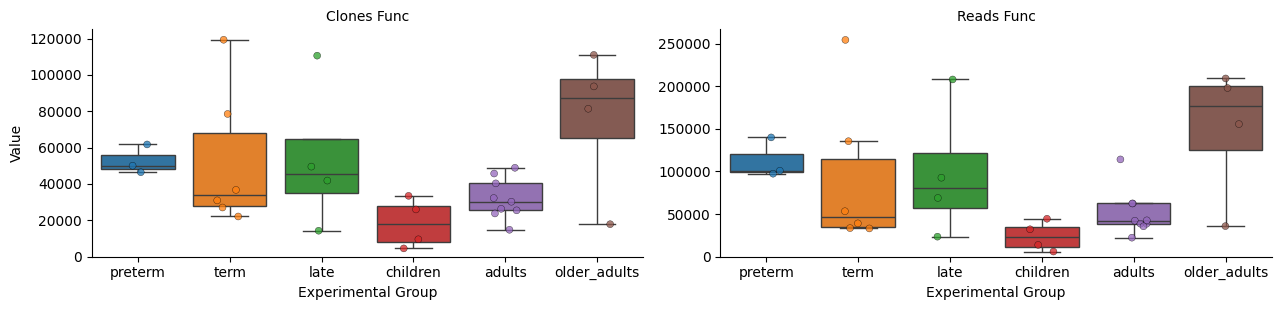

In [9]:
rsplot.clonoset_stats(clonoset_stats_subset, metadata=metadata, group="experimental_group", properties=["clones_func", "reads_func"], aspect=2)

In [10]:
clonoset_stats_subset.sort_values(by="reads_func")

,sample_id,chain,clones,clones_func,clones_func_singletons,clones_func_non_singletons,clones_nonfunc,clones_nonfunc_freq,reads,reads_func,reads_nonfunc,reads_nonfunc_freq,umi,umi_func,umi_nonfunc,umi_nonfunc_freq,reads_per_umi
11,c2_mnCD4_TRB_1,TRB,4667,4508,3481,1027,159,0.034069,6084,5912,172,0.028271,NaN,NaN,NaN,NaN,NaN
21,c4_mnCD4_TRB_1,TRB,9912,9515,6818,2697,397,0.040052,14155,13695,460,0.032497,NaN,NaN,NaN,NaN,NaN
20,a7_mnCD4_TRB_1,TRB,15395,14760,10071,4689,635,0.041247,22940,22220,720,0.031386,NaN,NaN,NaN,NaN,NaN
6,UCB4_nCD4_TRB_1,TRB,15004,14235,8453,5782,769,0.051253,24297,23395,902,0.037124,NaN,NaN,NaN,NaN,NaN
19,c5_mnCD4_TRB_1,TRB,26673,25952,21374,4578,721,0.027031,32840,32077,763,0.023234,NaN,NaN,NaN,NaN,NaN
13,UCB6_nCD4_TRB_1,TRB,23056,22069,14572,7497,987,0.042809,34149,33053,1096,0.032095,NaN,NaN,NaN,NaN,NaN
17,UCB12_mnCD4_TRB_1,TRB,28150,27005,22218,4787,1145,0.040675,34663,33459,1204,0.034734,NaN,NaN,NaN,NaN,NaN
25,a9_mnCD4_TRB_1,TRB,24536,23743,16874,6869,793,0.032320,36490,35572,918,0.025158,NaN,NaN,NaN,NaN,NaN
12,o5_mnCD4_TRB_1,TRB,19077,17835,9580,8255,1242,0.065105,37447,35797,1650,0.044062,NaN,NaN,NaN,NaN,NaN
7,a1_mnCD4_TRB_1,TRB,26520,25444,17282,8162,1076,0.040573,39766,38486,1280,0.032188,NaN,NaN,NaN,NaN,NaN


In [11]:
metadata_check = clonoset_stats_subset.merge(metadata_raw, on="sample_id", validate="one_to_one")
assert (metadata_check["reads_func"] == metadata_check["UMI_functional"]).all()
assert (metadata_check["clones_func"] == metadata_check["clonotypes_functional"]).all()
depth_summary = clonoset_stats_subset.merge(metadata, on="sample_id", validate="one_to_one")
depth_summary.groupby("experimental_group", observed=True)[["clones_func", "reads_func"]].agg(["min", "median", "max"])

clones_func                  reads_func                  
                           min   median     max        min    median     max
experimental_group                                                          
preterm                  46447  50019.0   61724      97361  100848.0  140002
term                     22069  33816.0  119344      33053   46157.0  254528
late                     14235  45689.0  110597      23395   80781.5  208078
children                  4508  17733.5   33429       5912   22886.0   44444
adults                   14760  30199.0   48869      22220   42144.0  114159
older_adults             17835  87518.5  111009      35797  176862.0  209275

## Filters

Глубина функциональной части составляет от 5912 до 254528 наблюдений. Выбираем downsample 5000, чтобы сохранить все 30 образцов. Для проверки влияния глубины используем 2500. Такой выбор сохраняет группы, но уменьшает число обнаруживаемых редких клонотипов

Сохраняем `by_umi=True` как на семинаре, при этом repseq использует reads. Во всех выбранных образцах reads_func совпадает с UMI_functional из метаданных.

Для F2 фиксируем seed 100 в фильтре. В convergence и diversity задаём seed 100 в функции, а seed фильтра оставляем пустым. Это даёт три разные воспроизводимые подвыборки. Усредняем результаты по трём повторам.

In [12]:
downsample = 5000
func_filter = clf.Filter(functionality="f", by_umi=True)
downsample_filter = clf.Filter(functionality="f", downsample=downsample, by_umi=True, seed=100)
# Для повторов случайность задаёт seed функции.
iteration_filter = clf.Filter(functionality="f", downsample=downsample, by_umi=True)
assert clonoset_stats_subset["reads_func"].min() >= downsample
assert clonoset_stats_subset["umi_func"].isna().all()
downsample_filter

## CDR3 properties

In [13]:
cdr3_properties = stats.calc_cdr3_properties(clonosets_subset, cl_filter=func_filter, cpu=4)
cdr3_properties

Using 4 cores


CalcCDR3aaProperties |#-------------------------------------------------| 1/30 calcultaion(s) processed
CalcCDR3aaProperties |###-----------------------------------------------| 2/30 calcultaion(s) processed


CalcCDR3aaProperties |######--------------------------------------------| 4/30 calcultaion(s) processed


CalcCDR3aaProperties |##########----------------------------------------| 6/30 calcultaion(s) processed
CalcCDR3aaProperties |###########---------------------------------------| 7/30 calcultaion(s) processed


CalcCDR3aaProperties |###############-----------------------------------| 9/30 calcultaion(s) processed
CalcCDR3aaProperties |################----------------------------------| 10/30 calcultaion(s) processed
CalcCDR3aaProperties |##################--------------------------------| 11/30 calcultaion(s) processed
CalcCDR3aaProperties |####################------------------------------| 12/30 calcultaion(s) processed
CalcCDR3aaProperties |#####################-----------------------------| 13/30 calcultaion(s) processed


CalcCDR3aaProperties |#########################-------------------------| 15/30 calcultaion(s) processed
CalcCDR3aaProperties |##########################------------------------| 16/30 calcultaion(s) processed
CalcCDR3aaProperties |############################----------------------| 17/30 calcultaion(s) processed


... (2 outputs left out)

CalcCDR3aaProperties |########################################----------| 24/30 calcultaion(s) processed
CalcCDR3aaProperties |#########################################---------| 25/30 calcultaion(s) processed


CalcCDR3aaProperties |#############################################-----| 27/30 calcultaion(s) processed
CalcCDR3aaProperties |##############################################----| 28/30 calcultaion(s) processed


CalcCDR3aaProperties |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,mean_cdr3nt_len,mean_insert_size,zero_insert_freq,mean_frequency,cdr3_5_hydropathy,cdr3_full_hydropathy,cdr3_5_charge,cdr3_full_charge,...,cdr3_5_turn,cdr3_full_turn,cdr3_5_alpha,cdr3_full_alpha,cdr3_5_beta,cdr3_full_beta,cdr3_5_core,cdr3_full_core,cdr3_5_disorder,cdr3_full_disorder
0,a5_mnCD4_TRB_1,TRB,43.693769,7.480418,0.020375,0.000020,-3.905897,-3.699669,0.072259,-0.336180,...,5.885105,15.186346,4.474704,14.326838,4.803271,14.251321,0.288793,0.784359,2.481110,2.914558
1,a13_mnCD4_TRB_1,TRB,43.742383,7.479997,0.021118,0.000031,-3.704198,-3.723470,0.129034,-0.319263,...,5.822250,15.144052,4.496033,14.376130,4.826838,14.286198,0.289599,0.787836,2.355211,2.782104
2,a3_mnCD4_TRB_1,TRB,43.473321,7.604426,0.021936,0.000022,-3.795965,-3.355254,0.093017,-0.326304,...,5.865496,15.074761,4.488347,14.274366,4.803612,14.188061,0.288714,0.781489,2.440120,2.801564
3,UCB10_nCD4_TRB_1,TRB,42.659185,6.214106,0.051621,0.000008,-3.774383,-3.432034,0.131447,-0.272622,...,5.808512,14.739529,4.502695,14.017260,4.833382,13.953409,0.290439,0.767275,2.309746,2.530209
4,UCB5_nCD4_TRB_2,TRB,40.406860,2.940197,0.289555,0.000022,-4.757558,-3.512079,-0.016431,-0.298449,...,5.831050,13.955976,4.535339,13.279585,4.810224,13.226433,0.293906,0.728101,2.298687,2.174837
5,UCB9_nCD4_TRB_2,TRB,42.846534,6.214199,0.057007,0.000009,-3.711005,-3.331997,0.148127,-0.295697,...,5.777485,14.752849,4.520114,14.107939,4.837992,14.029632,0.290647,0.770879,2.268798,2.512817
6,UCB4_nCD4_TRB_1,TRB,42.623338,6.165976,0.053900,0.000070,-3.657341,-3.354875,0.085061,-0.354862,...,5.834073,14.722693,4.488573,14.012507,4.831272,13.946573,0.290446,0.767369,2.293140,2.483009
7,a1_mnCD4_TRB_1,TRB,43.414410,7.593281,0.019825,0.000039,-3.806782,-3.703336,0.133659,-0.265707,...,5.820975,15.027118,4.499575,14.268155,4.822275,14.172570,0.289014,0.779843,2.355116,2.696305
8,o6_mnCD4_TRB_2,TRB,43.461947,7.081973,0.023362,0.000009,-3.973663,-3.456339,0.074600,-0.293948,...,5.893835,15.110378,4.476302,14.240984,4.794362,14.173627,0.289013,0.780200,2.519847,2.917334
9,a11_mnCD4_TRB_1,TRB,44.108381,7.936776,0.018537,0.000038,-3.553835,-3.524956,0.134060,-0.259827,...,5.857520,15.311865,4.473015,14.475639,4.822125,14.384579,0.289283,0.793819,2.413951,2.926133


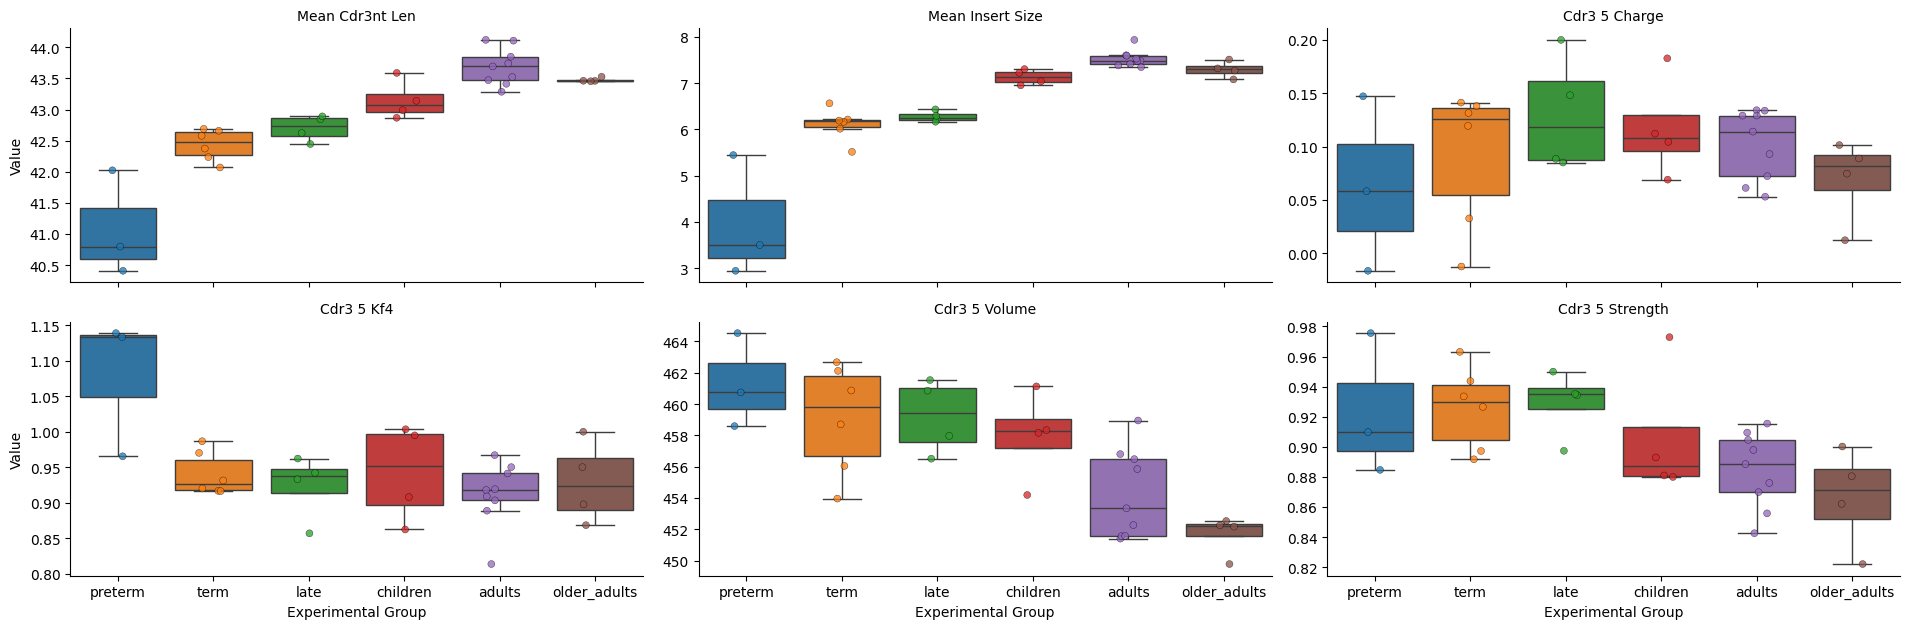

In [14]:
rsplot.cdr3aa_stats(cdr3_properties,
                     metadata=metadata,
                     properties=None,
                     group="experimental_group",
                     split=None,
                     palette=None,
                     height=3.2,
                     aspect=2,
                    )

In [15]:
cdr3_summary = cdr3_properties.merge(metadata, on="sample_id").groupby(
    "experimental_group", observed=True)[["mean_cdr3nt_len", "mean_insert_size"]].mean()
cdr3_summary

,mean_cdr3nt_len,mean_insert_size
experimental_group,,
preterm,41.075759,3.960850
term,42.434369,6.110462
late,42.701622,6.276619
children,43.147328,7.130464
adults,43.690549,7.530213
older_adults,43.476987,7.296751


В preterm средняя длина CDR3 по образцам составляет 41,08 нт, в adults 43,69 нт. Среднее число вставленных нуклеотидов также ниже в preterm, 3,96 против 7,53 в adults. Группы term и late занимают промежуточное положение.

## CDR3len distributions

In [16]:
preterm_late = clonosets_subset.query("experimental_group in ['preterm', 'late']")
preterm_late

,sample_id,chain,filename,experimental_group,donor_id,subset,source
4,UCB5_nCD4_TRB_2,TRB,/home/anna/Bioinformatics305/homework_immune/d...,preterm,UCB5,nCD4,UCB
5,UCB9_nCD4_TRB_2,TRB,/home/anna/Bioinformatics305/homework_immune/d...,late,UCB9,nCD4,UCB
6,UCB4_nCD4_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...,late,UCB4,nCD4,UCB
18,UCB8_nCD4_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...,late,UCB8,nCD4,UCB
22,UCB1_nCD4_TRB_2,TRB,/home/anna/Bioinformatics305/homework_immune/d...,preterm,UCB1,nCD4,UCB
26,UCB11_nCD4_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...,preterm,UCB11,nCD4,UCB
27,UCB7_nCD4_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...,late,UCB7,nCD4,UCB


In [17]:
cdr3_len_distribs = stats.cdr3_length_distributions(
                                                        preterm_late,
                                                        cl_filter=func_filter,
                                                        cpu=4,
                                                        count_by_freq=True,
                                                        seq_type="aa",
                                                        table="long",
                                                        zero_fill=True,
                                                        verbose=True,
                                                        drop_small_samples=False,
                                                    )
cdr3_len_distribs

Using 4 cores


CalcCDR3LengthDistribution |##############------------------------------------| 2/7 calcultaion(s) processed
CalcCDR3LengthDistribution |#####################-----------------------------| 3/7 calcultaion(s) processed
CalcCDR3LengthDistribution |############################----------------------| 4/7 calcultaion(s) processed
CalcCDR3LengthDistribution |###################################---------------| 5/7 calcultaion(s) processed
CalcCDR3LengthDistribution |##########################################--------| 6/7 calcultaion(s) processed
CalcCDR3LengthDistribution |##################################################| 7/7 calcultaion(s) processed


,sample_id,chain,cdr3_length,freq
0,UCB11_nCD4_TRB_1,TRB,4,0.000000
1,UCB11_nCD4_TRB_1,TRB,5,0.000007
2,UCB11_nCD4_TRB_1,TRB,6,0.000021
3,UCB11_nCD4_TRB_1,TRB,7,0.000129
4,UCB11_nCD4_TRB_1,TRB,8,0.000371
...,...,...,...,...
156,UCB9_nCD4_TRB_2,TRB,22,0.000053
157,UCB9_nCD4_TRB_2,TRB,23,0.000038
158,UCB9_nCD4_TRB_2,TRB,24,0.000010
159,UCB9_nCD4_TRB_2,TRB,25,0.000010


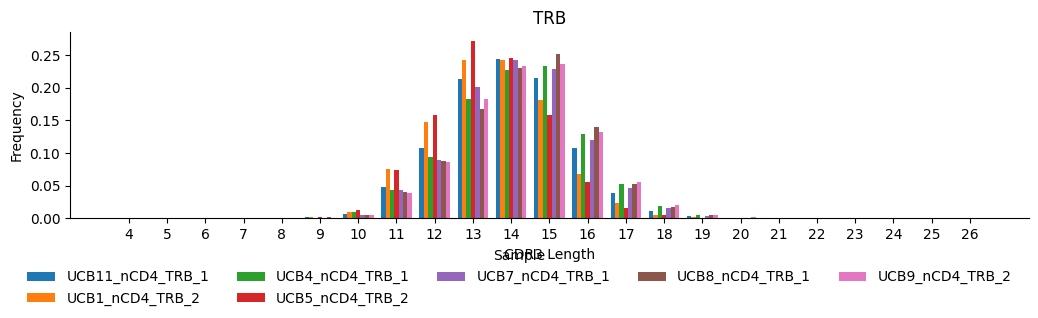

In [18]:
rsplot.cdr3_length_distributions(cdr3_len_distribs)

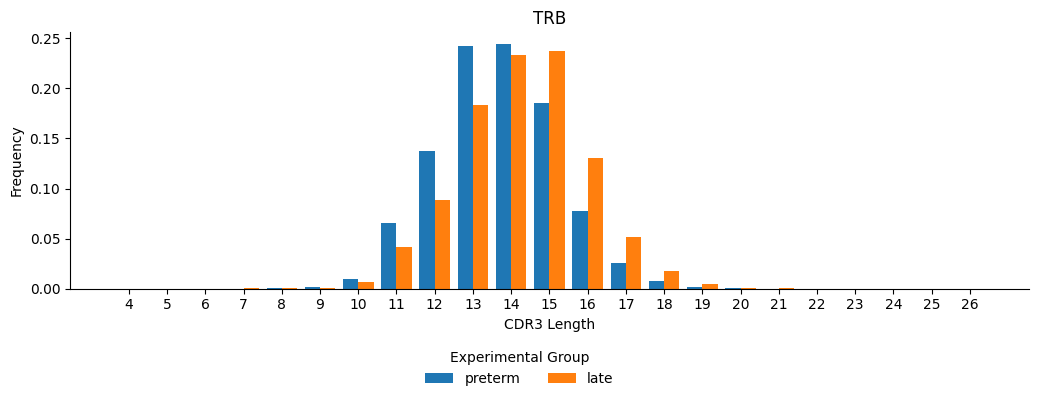

In [19]:
rsplot.cdr3_length_distributions(cdr3_len_distribs, metadata=metadata, group="experimental_group", height=4)

Распределения preterm и late сильно перекрываются. В preterm больше CDR3 длиной 11–13 аминокислот, а в late выше доля длин 15–17. Основная часть обоих распределений приходится на 12–16 аминокислот.

## Segment usage

### V-usage

In [20]:
v_usage = stats.calc_segment_usage(clonosets_subset, segment="v", cl_filter=func_filter, table="long", cpu=4)
v_usage.head()

Using 4 cores


CalcSegmentUsage |#-------------------------------------------------| 1/30 calcultaion(s) processed
CalcSegmentUsage |###-----------------------------------------------| 2/30 calcultaion(s) processed


CalcSegmentUsage |######--------------------------------------------| 4/30 calcultaion(s) processed


CalcSegmentUsage |##########----------------------------------------| 6/30 calcultaion(s) processed
CalcSegmentUsage |###########---------------------------------------| 7/30 calcultaion(s) processed


CalcSegmentUsage |###############-----------------------------------| 9/30 calcultaion(s) processed
CalcSegmentUsage |################----------------------------------| 10/30 calcultaion(s) processed
CalcSegmentUsage |##################--------------------------------| 11/30 calcultaion(s) processed
CalcSegmentUsage |####################------------------------------| 12/30 calcultaion(s) processed
CalcSegmentUsage |#####################-----------------------------| 13/30 calcultaion(s) processed


CalcSegmentUsage |#########################-------------------------| 15/30 calcultaion(s) processed
CalcSegmentUsage |##########################------------------------| 16/30 calcultaion(s) processed
CalcSegmentUsage |############################----------------------| 17/30 calcultaion(s) processed


... (2 outputs left out)

CalcSegmentUsage |########################################----------| 24/30 calcultaion(s) processed
CalcSegmentUsage |#########################################---------| 25/30 calcultaion(s) processed


CalcSegmentUsage |#############################################-----| 27/30 calcultaion(s) processed
CalcSegmentUsage |##############################################----| 28/30 calcultaion(s) processed


CalcSegmentUsage |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,v,usage
0,a5_mnCD4_TRB_1,TRB,TRBV1,0.000324
1,a13_mnCD4_TRB_1,TRB,TRBV1,0.000308
2,a3_mnCD4_TRB_1,TRB,TRBV1,0.000080
3,UCB10_nCD4_TRB_1,TRB,TRBV1,0.000369
4,UCB5_nCD4_TRB_2,TRB,TRBV1,0.000317


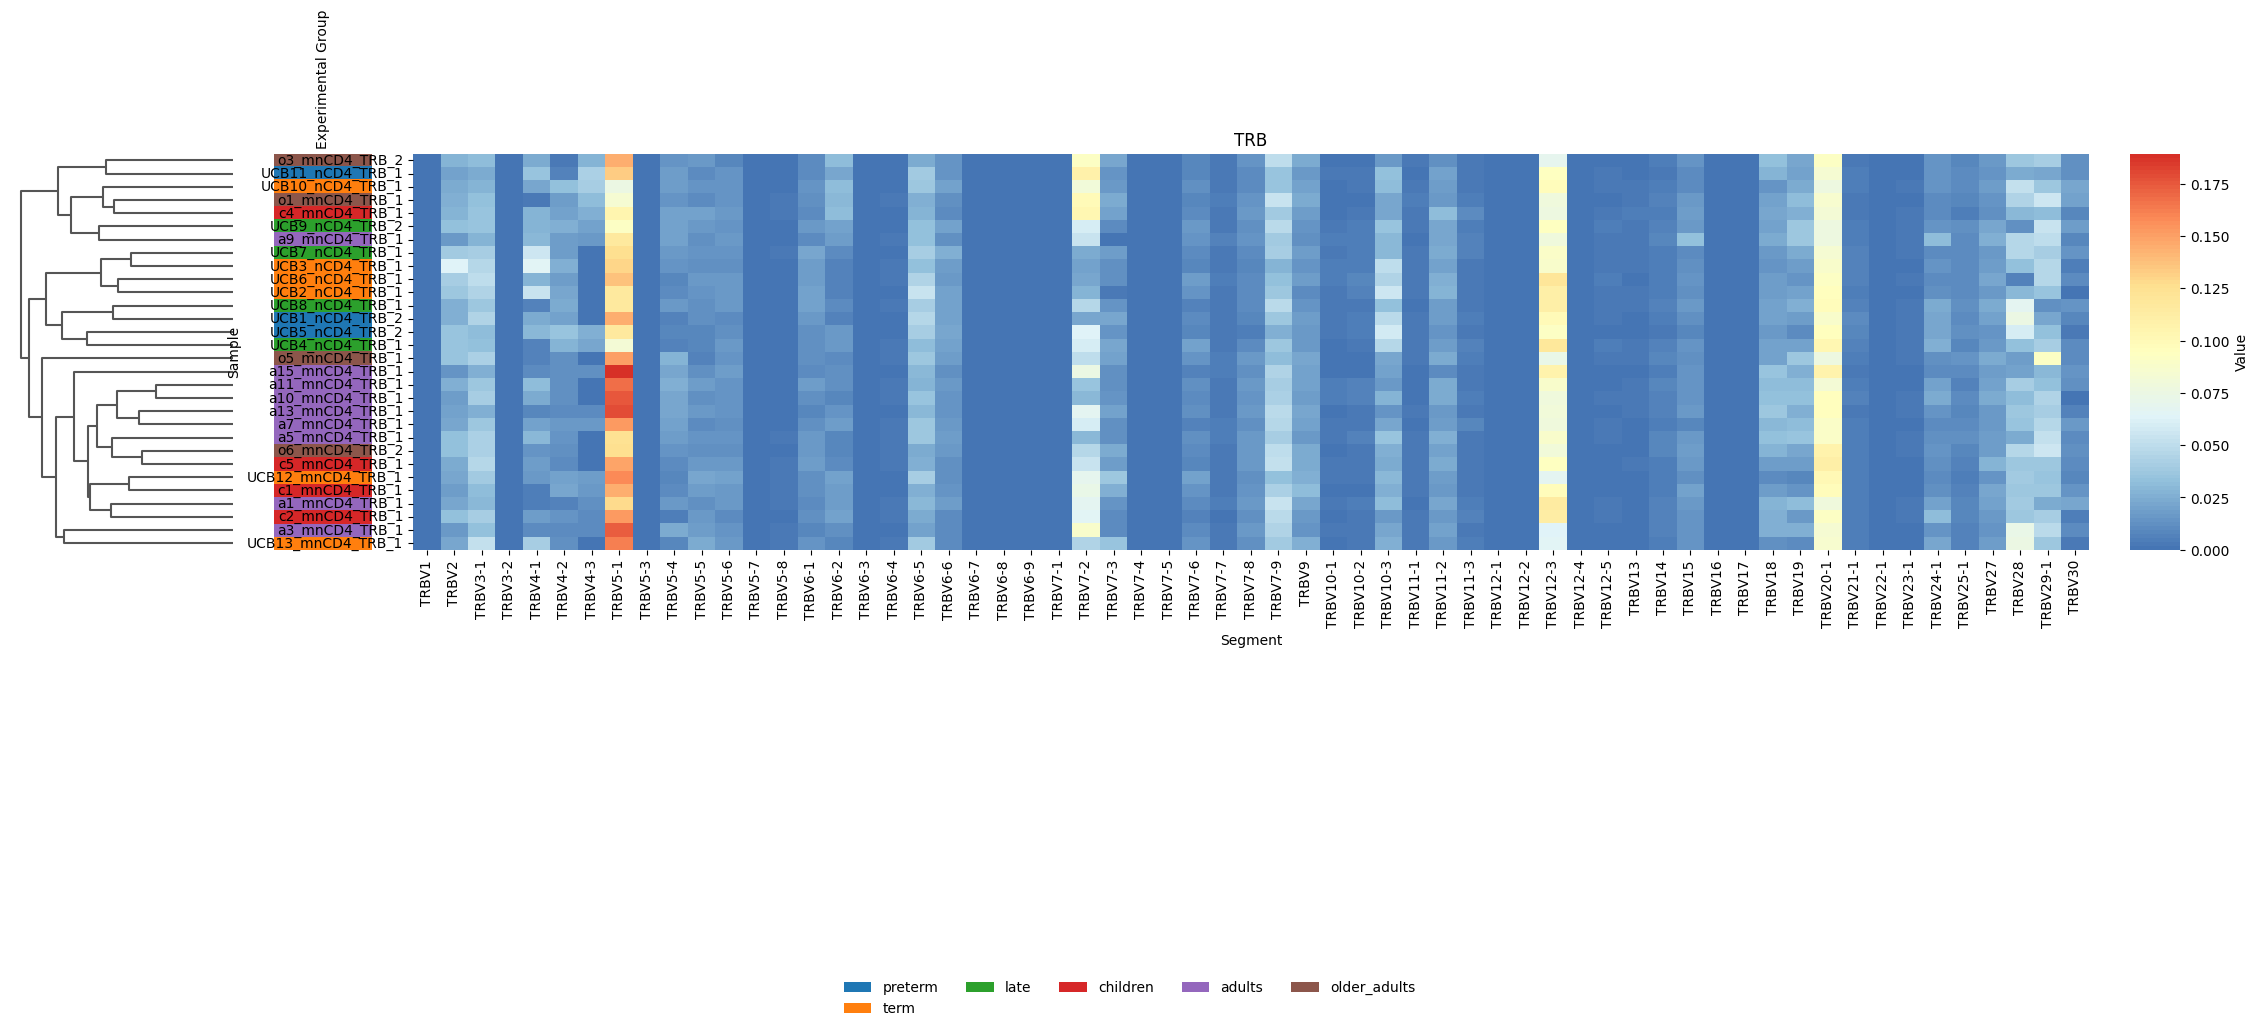

In [21]:
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="heatmap", height=7)

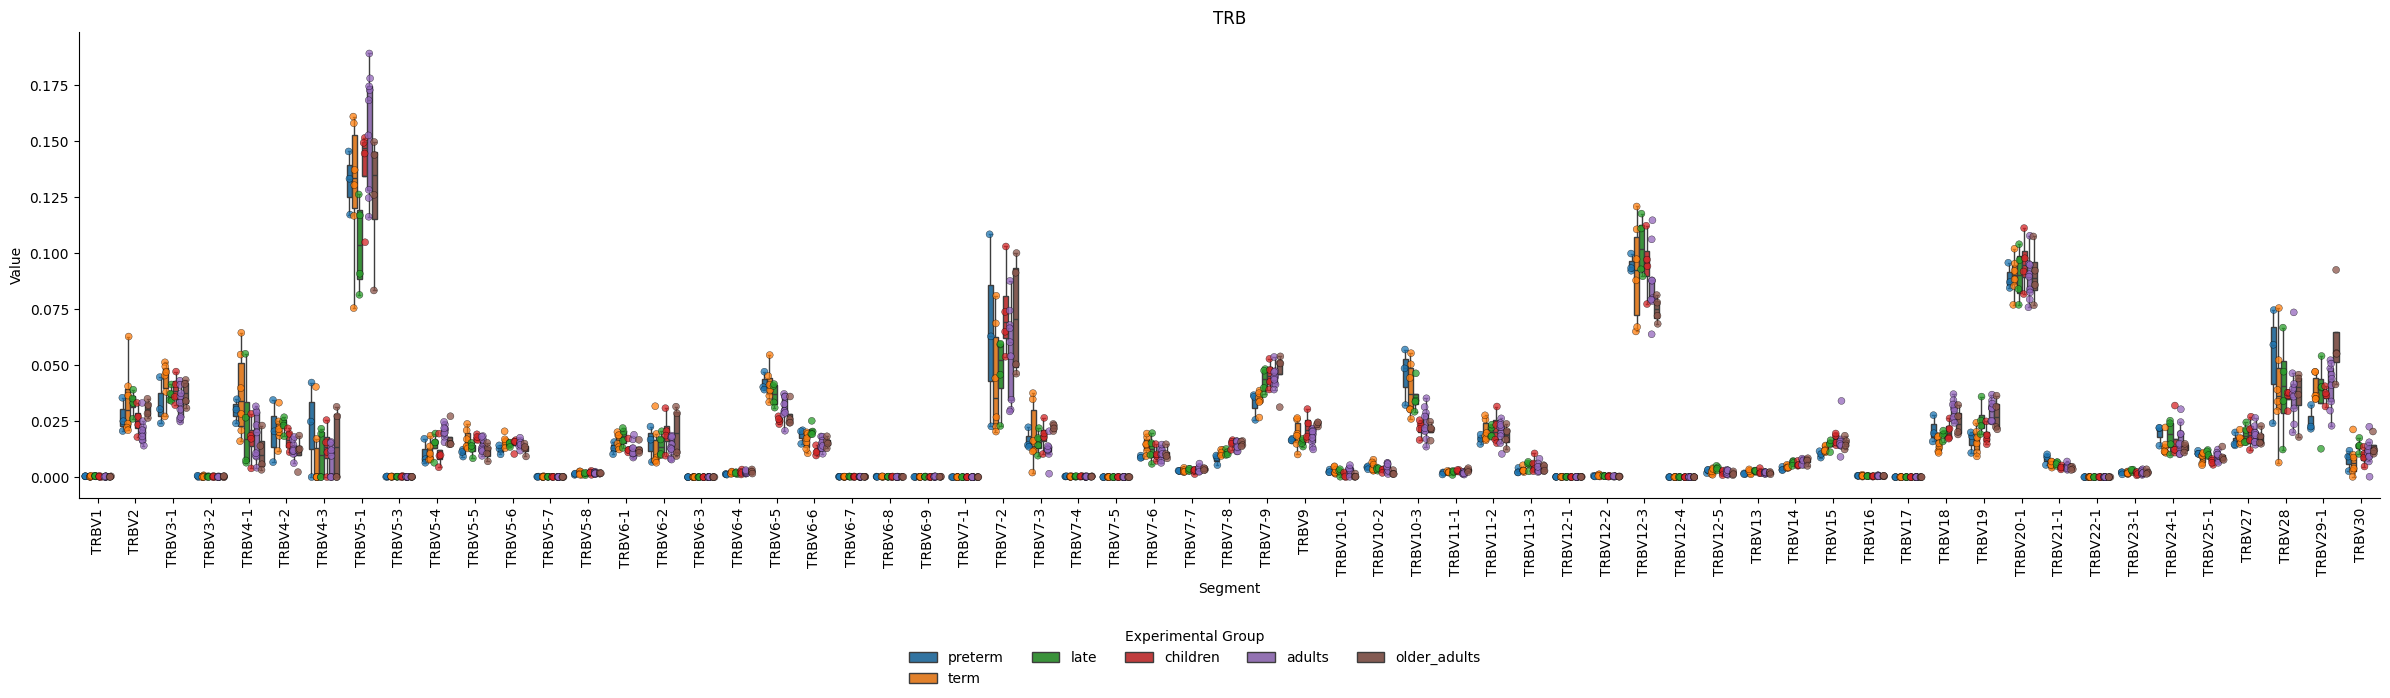

In [22]:
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="boxplot", height=7, )

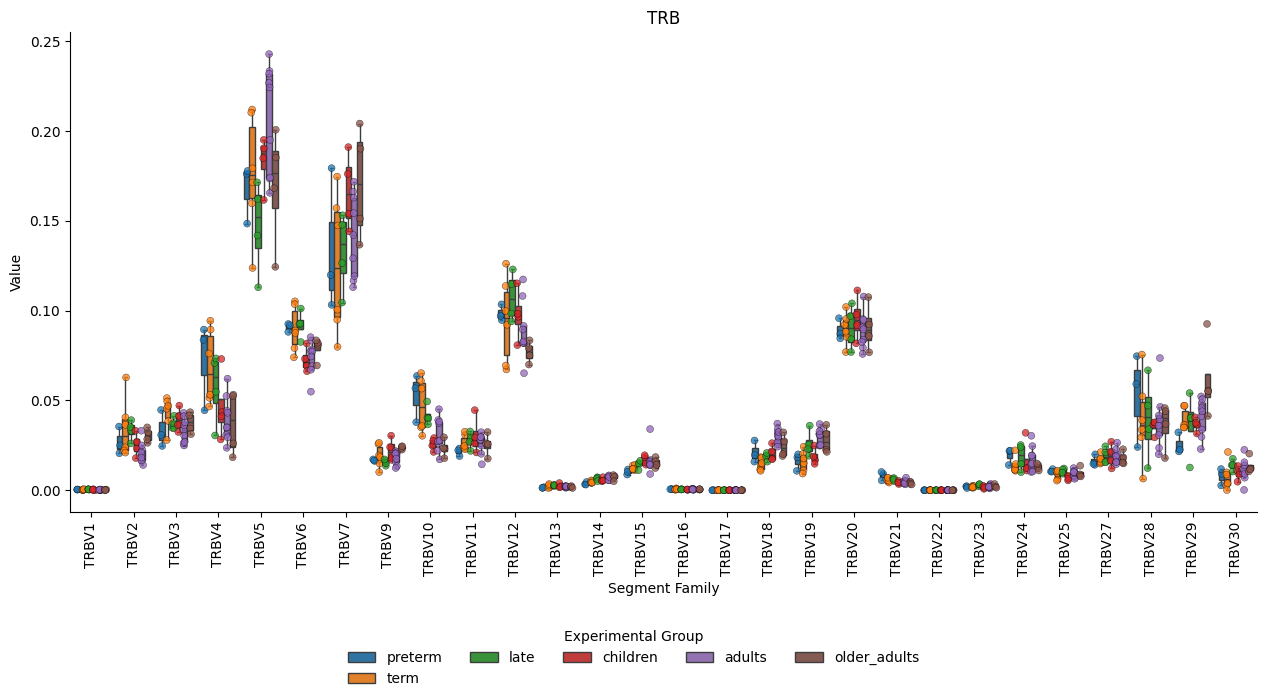

In [23]:
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="boxplot", height=7, combine_families=True)

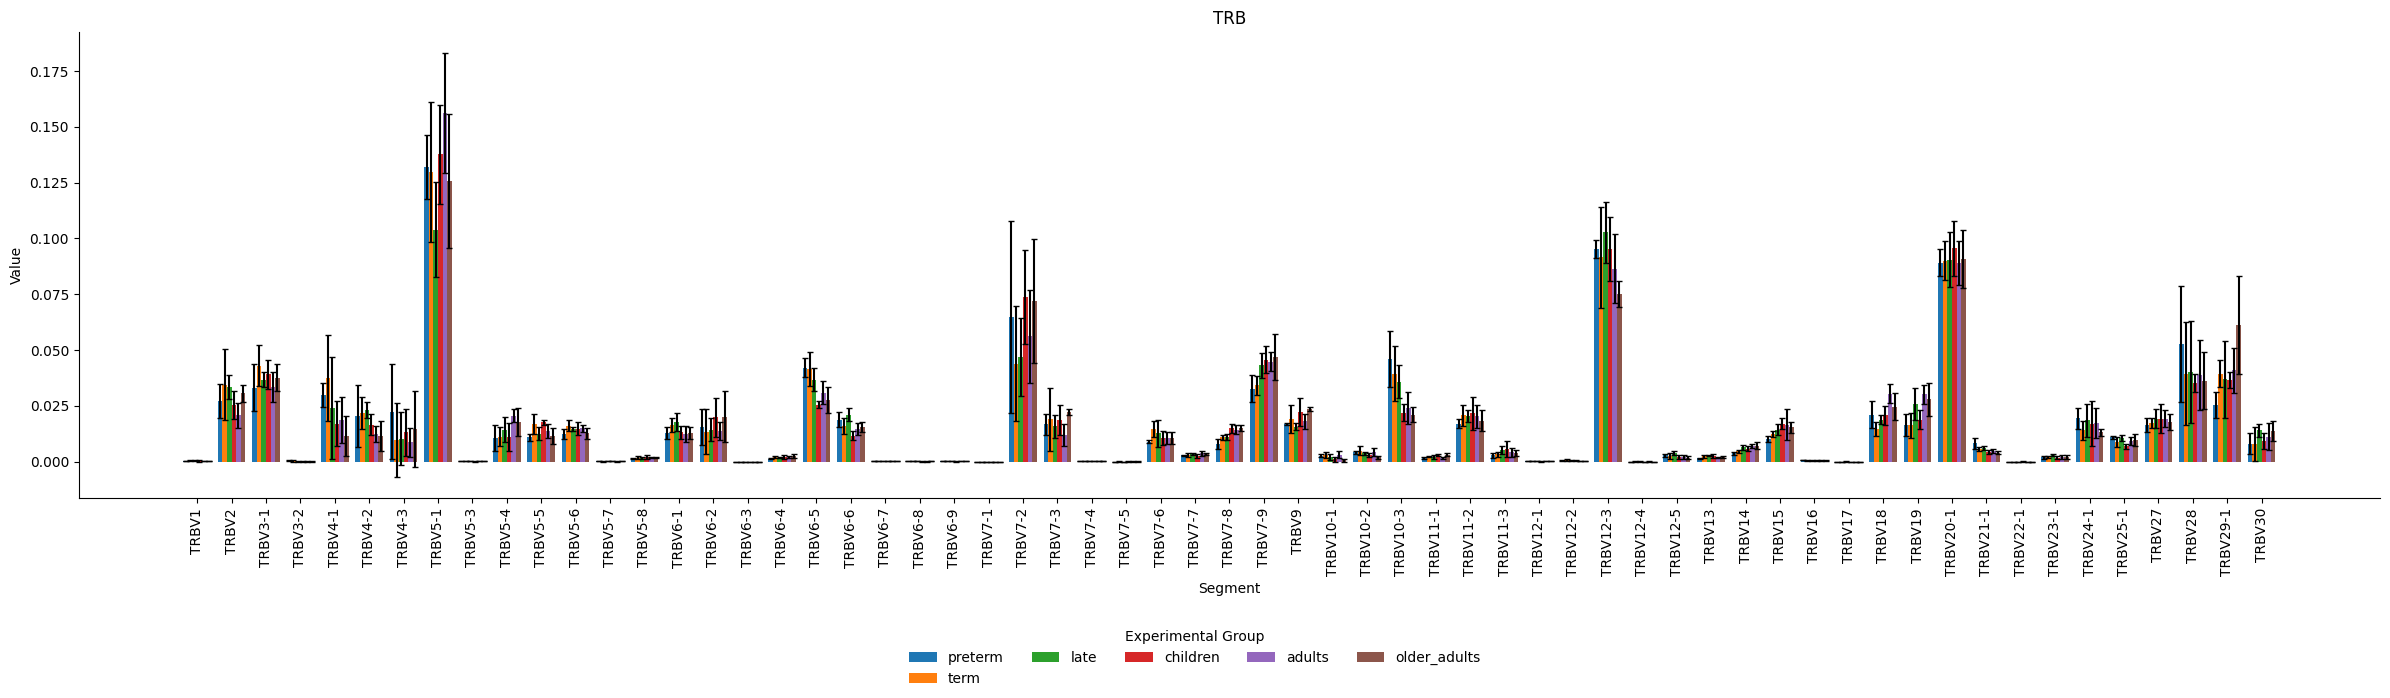

In [24]:
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7)

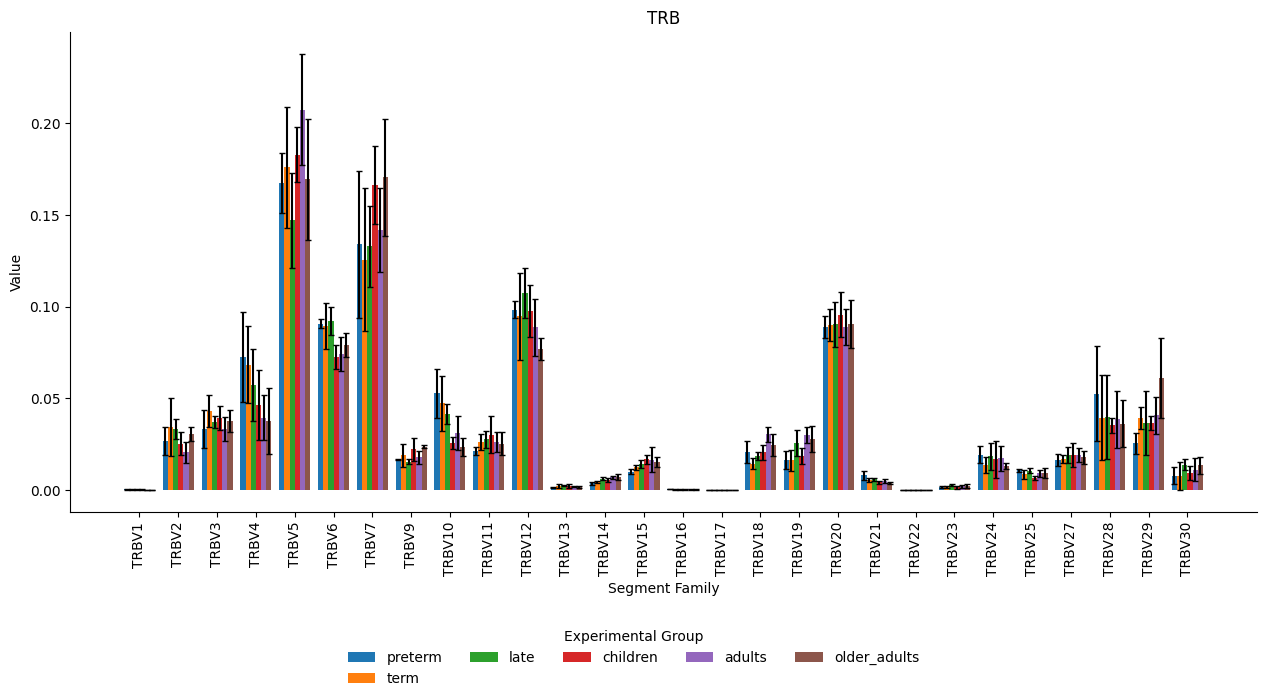

In [25]:
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7, combine_families=True)

### J-usage

In [26]:
j_usage = stats.calc_segment_usage(clonosets_subset, segment="j", cl_filter=func_filter, table="long", cpu=4)
j_usage.head()

Using 4 cores


CalcSegmentUsage |#-------------------------------------------------| 1/30 calcultaion(s) processed
CalcSegmentUsage |###-----------------------------------------------| 2/30 calcultaion(s) processed


CalcSegmentUsage |######--------------------------------------------| 4/30 calcultaion(s) processed


CalcSegmentUsage |##########----------------------------------------| 6/30 calcultaion(s) processed
CalcSegmentUsage |###########---------------------------------------| 7/30 calcultaion(s) processed


CalcSegmentUsage |###############-----------------------------------| 9/30 calcultaion(s) processed
CalcSegmentUsage |################----------------------------------| 10/30 calcultaion(s) processed
CalcSegmentUsage |##################--------------------------------| 11/30 calcultaion(s) processed
CalcSegmentUsage |####################------------------------------| 12/30 calcultaion(s) processed
CalcSegmentUsage |#####################-----------------------------| 13/30 calcultaion(s) processed


CalcSegmentUsage |#########################-------------------------| 15/30 calcultaion(s) processed
CalcSegmentUsage |##########################------------------------| 16/30 calcultaion(s) processed
CalcSegmentUsage |############################----------------------| 17/30 calcultaion(s) processed


CalcSegmentUsage |###############################-------------------| 19/30 calcultaion(s) processed
CalcSegmentUsage |#################################-----------------| 20/30 calcultaion(s) processed


CalcSegmentUsage |########################################----------| 24/30 calcultaion(s) processed
CalcSegmentUsage |#########################################---------| 25/30 calcultaion(s) processed


CalcSegmentUsage |#############################################-----| 27/30 calcultaion(s) processed
CalcSegmentUsage |##############################################----| 28/30 calcultaion(s) processed


CalcSegmentUsage |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,j,usage
0,a5_mnCD4_TRB_1,TRB,TRBJ1-1,0.103557
1,a13_mnCD4_TRB_1,TRB,TRBJ1-1,0.098946
2,a3_mnCD4_TRB_1,TRB,TRBJ1-1,0.100067
3,UCB10_nCD4_TRB_1,TRB,TRBJ1-1,0.098260
4,UCB5_nCD4_TRB_2,TRB,TRBJ1-1,0.097860


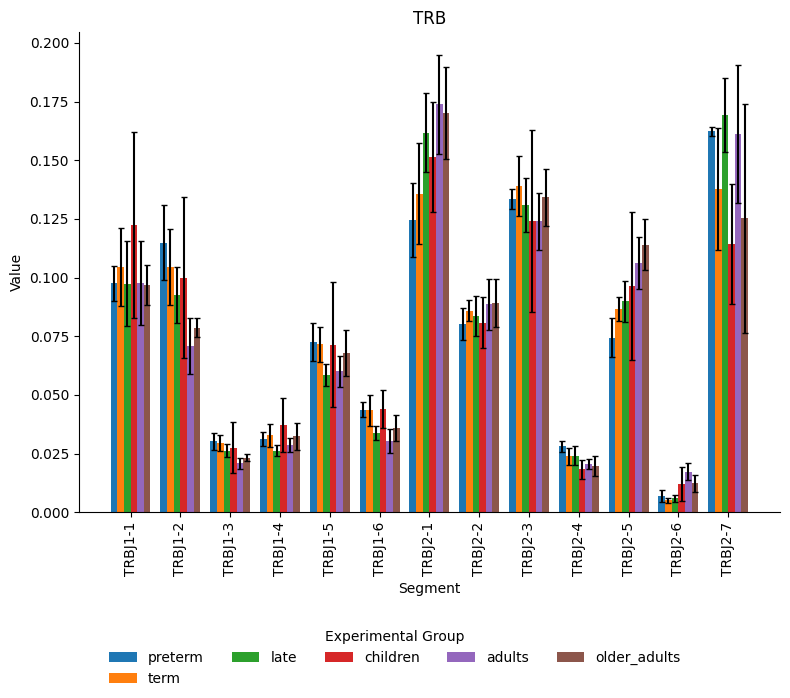

In [27]:
rsplot.segment_usage(j_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7)

В среднем по образцам чаще используются TRBV5-1 (13,5%), TRBV20-1 (9,0%) и TRBV12-3 (9,0%). TRBV5-1 лидирует во всех группах, его средняя доля меняется от 10,4% в late до 15,6% в adults. Среди J-сегментов наиболее часты TRBJ2-1 (15,6%) и TRBJ2-7 (14,7%). В preterm и late чаще встречается TRBJ2-7, а в adults и older_adults TRBJ2-1.

## Convergence

In [28]:
convergence = stats.calc_convergence(clonosets_subset, cl_filter=iteration_filter,
                                     seed=100, iterations=3, cpu=4)
convergence

CalcConvergence settings: seed=100, downsample=5000, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 4 cores


CalcClonosetStats |#-------------------------------------------------| 1/30 calcultaion(s) processed
CalcClonosetStats |###-----------------------------------------------| 2/30 calcultaion(s) processed


CalcClonosetStats |######--------------------------------------------| 4/30 calcultaion(s) processed


CalcClonosetStats |##########----------------------------------------| 6/30 calcultaion(s) processed
CalcClonosetStats |###########---------------------------------------| 7/30 calcultaion(s) processed


CalcClonosetStats |###############-----------------------------------| 9/30 calcultaion(s) processed
CalcClonosetStats |################----------------------------------| 10/30 calcultaion(s) processed
CalcClonosetStats |##################--------------------------------| 11/30 calcultaion(s) processed
CalcClonosetStats |####################------------------------------| 12/30 calcultaion(s) processed
CalcClonosetStats |#####################-----------------------------| 13/30 calcultaion(s) processed


CalcClonosetStats |#########################-------------------------| 15/30 calcultaion(s) processed
CalcClonosetStats |##########################------------------------| 16/30 calcultaion(s) processed
CalcClonosetStats |############################----------------------| 17/30 calcultaion(s) processed
CalcClonosetStats |##############################--------------------| 18/30 calcultaion(s) processed


... (11 outputs left out)

CalcConvergence |########################################----------| 24/30 calcultaion(s) processed
CalcConvergence |#########################################---------| 25/30 calcultaion(s) processed


CalcConvergence |#############################################-----| 27/30 calcultaion(s) processed
CalcConvergence |##############################################----| 28/30 calcultaion(s) processed


CalcConvergence |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,convergence,convergence_v,convergence_vj
0,a5_mnCD4_TRB_1,TRB,1.001704,1.000284,1.000284
1,a13_mnCD4_TRB_1,TRB,1.002513,1.000209,1.000209
2,a3_mnCD4_TRB_1,TRB,1.002138,1.000620,1.000620
3,UCB10_nCD4_TRB_1,TRB,1.005558,1.000751,1.000751
4,UCB5_nCD4_TRB_2,TRB,1.069459,1.015417,1.015417
5,UCB9_nCD4_TRB_2,TRB,1.004799,1.000819,1.000819
6,UCB4_nCD4_TRB_1,TRB,1.005774,1.001532,1.001532
7,a1_mnCD4_TRB_1,TRB,1.001947,1.000072,1.000072
8,o6_mnCD4_TRB_2,TRB,1.002677,1.000616,1.000616
9,a11_mnCD4_TRB_1,TRB,1.002315,1.000434,1.000434


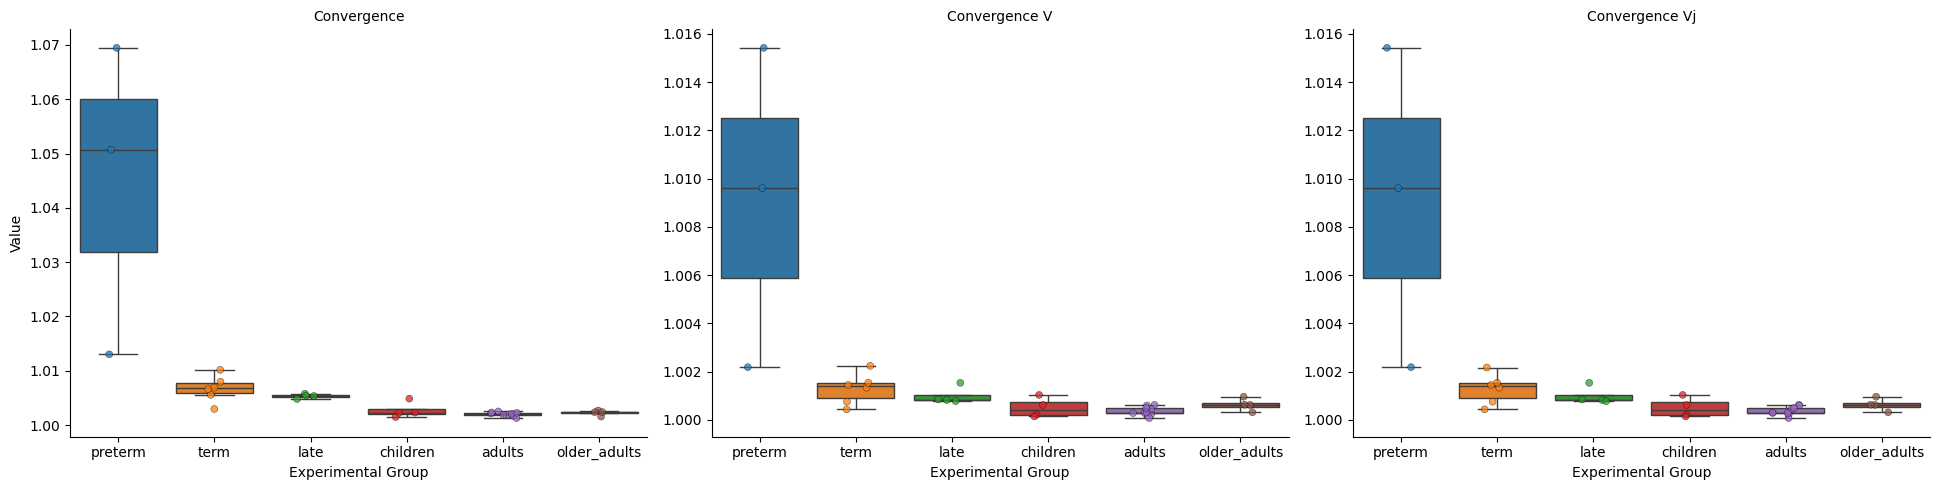

In [29]:
rsplot.convergence(convergence,
                     metadata=metadata,
                     group="experimental_group",
                     height=5,
                     aspect=1.3
                  )

Медиана convergence максимальна в preterm, 1,051. В остальных группах она составляет 1,002–1,007. При учёте V-гена значения приближаются к единице, но preterm сохраняет более высокую медиану 1,010. то есть в этой группе несколько чаще встречаются разные CDR3nt, кодирующие одинаковую CDR3aa

## Diversity stats

In [30]:
diversity_stats = stats.calc_diversity_stats(clonosets_subset, cl_filter=iteration_filter,
                                             seed=100, cpu=4, iterations=3,
                                             drop_small_samples=False)
diversity_stats

CalcDiversityStats settings: seed=100, downsample=5000, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 4 cores


CalcClonosetStats |#-------------------------------------------------| 1/30 calcultaion(s) processed
CalcClonosetStats |###-----------------------------------------------| 2/30 calcultaion(s) processed


CalcClonosetStats |######--------------------------------------------| 4/30 calcultaion(s) processed


CalcClonosetStats |##########----------------------------------------| 6/30 calcultaion(s) processed
CalcClonosetStats |###########---------------------------------------| 7/30 calcultaion(s) processed


CalcClonosetStats |###############-----------------------------------| 9/30 calcultaion(s) processed
CalcClonosetStats |################----------------------------------| 10/30 calcultaion(s) processed
CalcClonosetStats |##################--------------------------------| 11/30 calcultaion(s) processed
CalcClonosetStats |####################------------------------------| 12/30 calcultaion(s) processed
CalcClonosetStats |#####################-----------------------------| 13/30 calcultaion(s) processed


CalcClonosetStats |#########################-------------------------| 15/30 calcultaion(s) processed
CalcClonosetStats |##########################------------------------| 16/30 calcultaion(s) processed
CalcClonosetStats |############################----------------------| 17/30 calcultaion(s) processed


... (11 outputs left out)

CalcDiversityStats |########################################----------| 24/30 calcultaion(s) processed
CalcDiversityStats |#########################################---------| 25/30 calcultaion(s) processed


CalcDiversityStats |#############################################-----| 27/30 calcultaion(s) processed
CalcDiversityStats |##############################################----| 28/30 calcultaion(s) processed


CalcDiversityStats |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,diversity,norm_shannon_wiener,clonality,shannon_wiener,chao1,richness,ace,goods_coverage,d50,simpson,inverse_simpson,gini_simpson,berger_parker,gini_coefficient
0,a5_mnCD4_TRB_1,TRB,4720.666667,0.997437,0.002563,8.438026,44803.097952,4720.666667,44761.424143,0.108533,0.470412,0.000224,4470.727290,0.999776,0.000733,0.052916
1,a13_mnCD4_TRB_1,TRB,4810.666667,0.998263,0.001737,8.463862,66666.968519,4810.666667,66474.391100,0.074133,0.480321,0.000216,4634.211860,0.999784,0.000600,0.036496
2,a3_mnCD4_TRB_1,TRB,4858.000000,0.998688,0.001312,8.477242,89496.657721,4858.000000,89684.537418,0.055733,0.485385,0.000212,4721.149046,0.999788,0.000667,0.027630
3,UCB10_nCD4_TRB_1,TRB,4898.333333,0.999080,0.000920,8.488831,122031.716362,4898.333333,122439.300130,0.040333,0.489622,0.000208,4801.540430,0.999792,0.000600,0.019925
4,UCB5_nCD4_TRB_2,TRB,4670.333333,0.996653,0.003347,8.420709,42405.892674,4670.333333,43464.516236,0.123533,0.464706,0.000231,4336.512237,0.999769,0.000933,0.062329
5,UCB9_nCD4_TRB_2,TRB,4897.000000,0.999056,0.000944,8.488356,122897.359643,4897.000000,123516.858484,0.040667,0.489482,0.000208,4797.308677,0.999792,0.000533,0.020187
6,UCB4_nCD4_TRB_1,TRB,4414.333333,0.994701,0.005299,8.348137,20404.058212,4414.333333,20471.330360,0.222333,0.433662,0.000252,3966.199680,0.999748,0.000800,0.104466
7,a1_mnCD4_TRB_1,TRB,4677.666667,0.996962,0.003038,8.424882,39843.300854,4677.666667,40111.618635,0.123733,0.465545,0.000228,4383.430336,0.999772,0.000800,0.060686
8,o6_mnCD4_TRB_2,TRB,4889.000000,0.998979,0.001021,8.486069,115673.321322,4889.000000,115531.266583,0.043733,0.488645,0.000209,4781.452694,0.999791,0.000600,0.021720
9,a11_mnCD4_TRB_1,TRB,4647.000000,0.996764,0.003236,8.416651,34983.277210,4647.000000,35148.722611,0.136400,0.462017,0.000230,4341.338794,0.999770,0.000800,0.065919


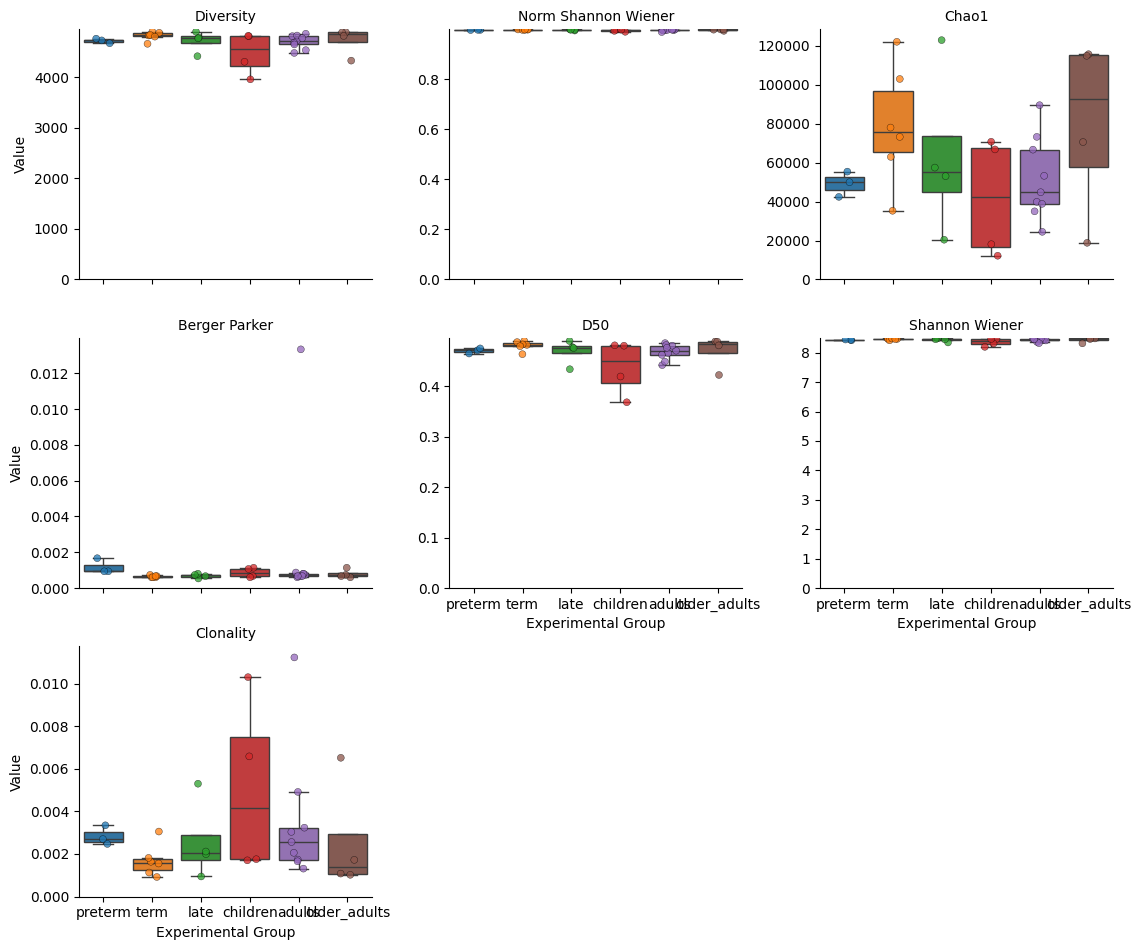

In [31]:
rsplot.diversity_stats(diversity_stats, metadata=metadata, group="experimental_group",
                       properties=["diversity", "norm_shannon_wiener", "chao1", "berger_parker",
                                   "d50", "shannon_wiener", "clonality"])

In [32]:
diversity_summary = diversity_stats.merge(metadata, on="sample_id").groupby(
    "experimental_group", observed=True)[["diversity", "shannon_wiener", "clonality"]].median()
diversity_summary

,diversity,shannon_wiener,clonality
experimental_group,,,
preterm,4727.000000,8.438202,0.002700
term,4828.833333,8.468835,0.001594
late,4774.833333,8.453695,0.002056
children,4557.000000,8.387889,0.004170
adults,4720.666667,8.438026,0.002563
older_adults,4850.333333,8.474878,0.001402


При глубине 5000 медиана diversity меняется от 4557 в children до 4850 в older_adults. Медианы Shannon составляют 8,39–8,47, clonality 0,0014–0,0042. Репертуары имеют высокое разнообразие и низкое доминирование отдельных клонотипов. Chao1 значительно превышает наблюдаемое diversity и чувствителен к редким клонотипам

## Rarefaction

In [33]:
rarefaction_points_ucb = stats.calc_rarefaction_curve(
    clonosets_subset, cl_filter=func_filter, iterations=3, seed=100, cpu=4)
rarefaction_points_ucb.head()

Using 4 cores


CalcRarefactionPoints |#-------------------------------------------------| 1/30 calcultaion(s) processed
CalcRarefactionPoints |###-----------------------------------------------| 2/30 calcultaion(s) processed


CalcRarefactionPoints |######--------------------------------------------| 4/30 calcultaion(s) processed


CalcRarefactionPoints |##########----------------------------------------| 6/30 calcultaion(s) processed
CalcRarefactionPoints |###########---------------------------------------| 7/30 calcultaion(s) processed


CalcRarefactionPoints |###############-----------------------------------| 9/30 calcultaion(s) processed
CalcRarefactionPoints |################----------------------------------| 10/30 calcultaion(s) processed
CalcRarefactionPoints |##################--------------------------------| 11/30 calcultaion(s) processed
CalcRarefactionPoints |####################------------------------------| 12/30 calcultaion(s) processed
CalcRarefactionPoints |#####################-----------------------------| 13/30 calcultaion(s) processed


CalcRarefactionPoints |#########################-------------------------| 15/30 calcultaion(s) processed
CalcRarefactionPoints |##########################------------------------| 16/30 calcultaion(s) processed
CalcRarefactionPoints |############################----------------------| 17/30 calcultaion(s) processed


CalcRarefactionPoints |###################################---------------| 21/30 calcultaion(s) processed


CalcRarefactionPoints |########################################----------| 24/30 calcultaion(s) processed
CalcRarefactionPoints |#########################################---------| 25/30 calcultaion(s) processed


CalcRarefactionPoints |#############################################-----| 27/30 calcultaion(s) processed
CalcRarefactionPoints |##############################################----| 28/30 calcultaion(s) processed


CalcRarefactionPoints |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,rarefaction_depth,diversity
0,UCB10_nCD4_TRB_1,TRB,32,32.000000
1,UCB10_nCD4_TRB_1,TRB,100,100.000000
2,UCB10_nCD4_TRB_1,TRB,316,315.666667
3,UCB10_nCD4_TRB_1,TRB,1000,995.000000
4,UCB10_nCD4_TRB_1,TRB,3162,3123.333333


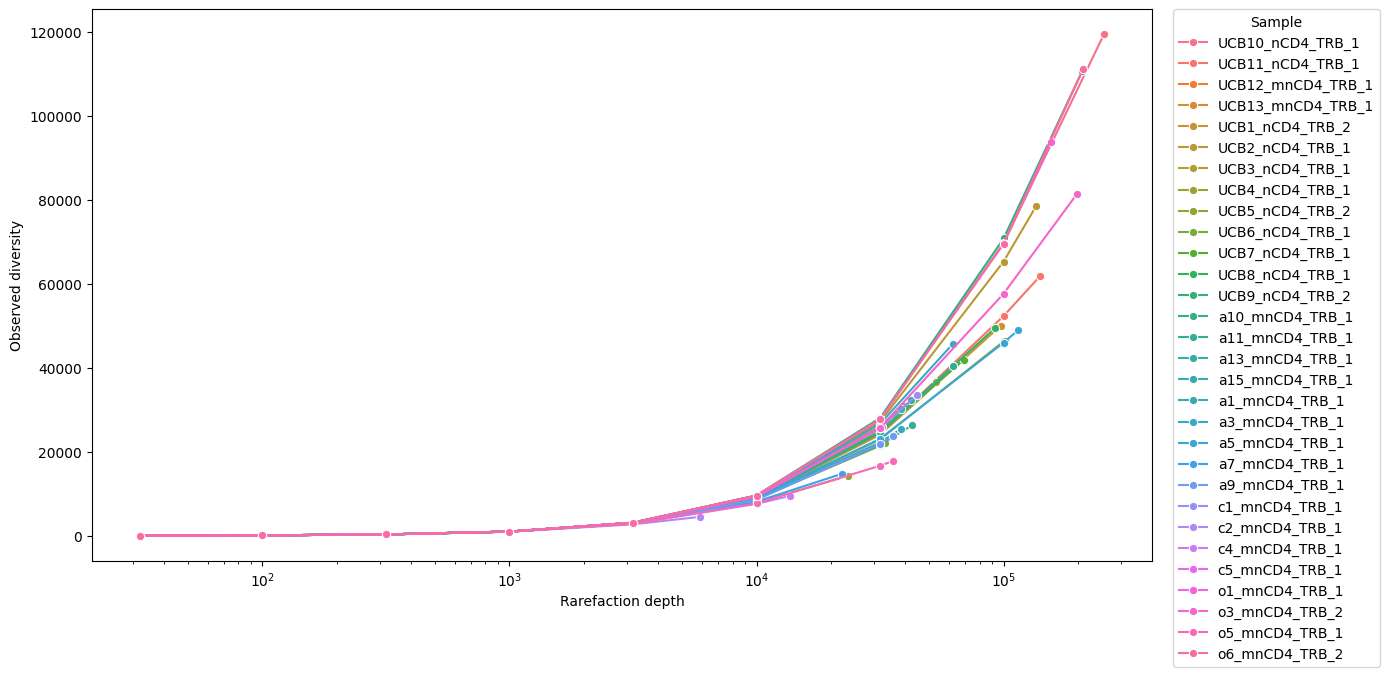

In [34]:
rsplot.rarefaction_curve(rarefaction_points_ucb, log_x=True, aspect=2, height=7)

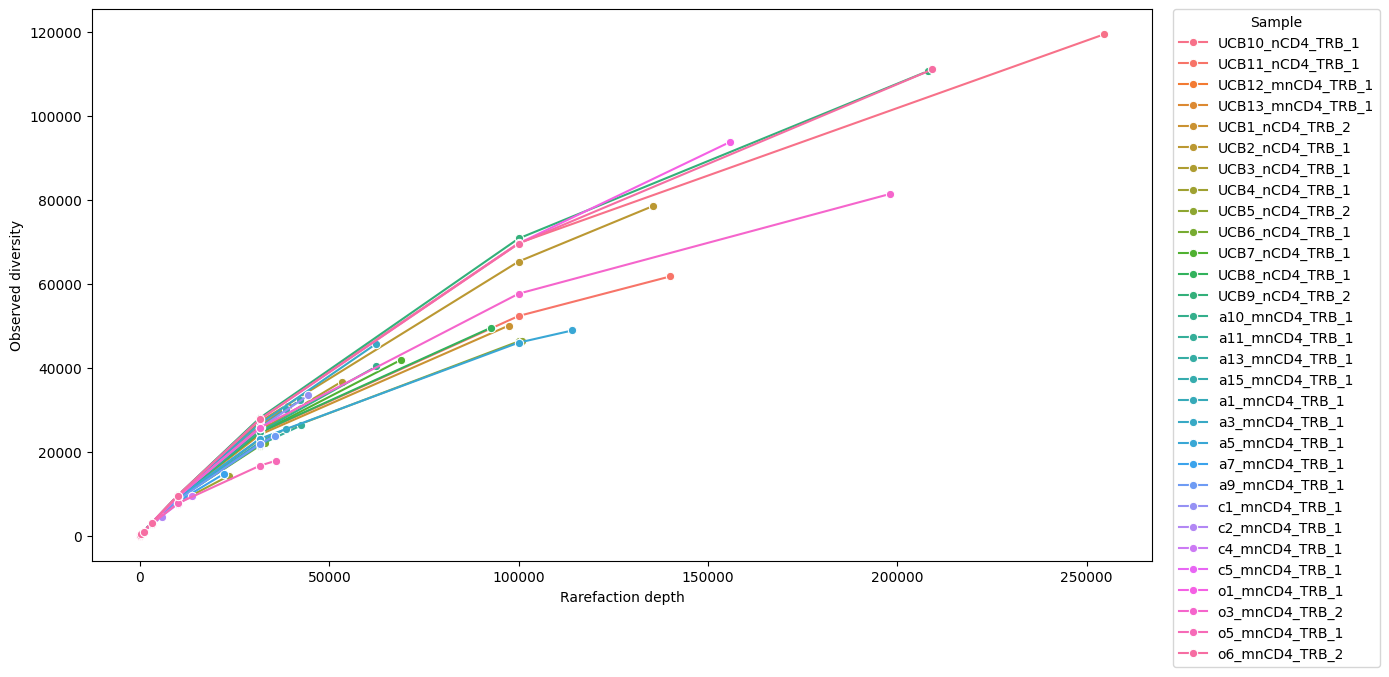

In [35]:
rsplot.rarefaction_curve(rarefaction_points_ucb, log_x=False, aspect=2, height=7)

Кривые продолжают расти до максимальной доступной глубины. Полного насыщения не видно, поэтому дополнительное секвенирование может выявить редкие клонотипы. Различия конечных значений также зависят от глубины исходных образцов.

## Beta-diversity

In [36]:
f2 = beta.metrics(clonosets_subset, cl_filter=downsample_filter,
                              overlap_type="aaV", metrics=["f2"], cpu=2)
beta_diversity = {"f2": f2}
assert np.allclose(f2, f2.T)
assert np.allclose(np.diag(f2), 1)
f2

Intersecting clones in clonosets
--------------------------------------------------
Overlap type: aaV


Reading clonosets |##################################################| 30/30 sample(s) processed
Using 2 cores


Intersecting clonosets |--------------------------------------------------| 2/435 pairs processed


Intersecting clonosets |--------------------------------------------------| 7/435 pairs processed


Intersecting clonosets |#-------------------------------------------------| 10/435 pairs processed


Intersecting clonosets |#-------------------------------------------------| 16/435 pairs processed


... (158 outputs left out)

Intersecting clonosets |#################################################-| 430/435 pairs processed


Intersecting clonosets |#################################################-| 432/435 pairs processed


Intersecting clonosets |#################################################-| 434/435 pairs processed
Intersecting clonosets |##################################################| 435/435 pairs processed


sample2,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB12_mnCD4_TRB_1,UCB13_mnCD4_TRB_1,UCB1_nCD4_TRB_2,UCB2_nCD4_TRB_1,UCB3_nCD4_TRB_1,UCB4_nCD4_TRB_1,UCB5_nCD4_TRB_2,UCB6_nCD4_TRB_1,...,a7_mnCD4_TRB_1,a9_mnCD4_TRB_1,c1_mnCD4_TRB_1,c2_mnCD4_TRB_1,c4_mnCD4_TRB_1,c5_mnCD4_TRB_1,o1_mnCD4_TRB_1,o3_mnCD4_TRB_2,o5_mnCD4_TRB_1,o6_mnCD4_TRB_2
sample1,,,,,,,,,,,,,,,,,,,,,
UCB10_nCD4_TRB_1,1.000000,0.003966,0.002166,0.002483,0.006009,0.001483,0.002029,0.003566,0.007990,0.001483,...,0.001483,0.001600,0.000600,0.001249,0.000746,0.001883,0.000800,0.000400,0.000883,0.000683
UCB11_nCD4_TRB_1,0.003966,1.000000,0.003283,0.005649,0.017098,0.002000,0.004278,0.003331,0.017401,0.001483,...,0.002483,0.000483,0.001883,0.002341,0.001712,0.000800,0.001683,0.001449,0.000883,0.001000
UCB12_mnCD4_TRB_1,0.002166,0.003283,1.000000,0.003849,0.007061,0.001566,0.003112,0.001000,0.009925,0.001200,...,0.002200,0.000400,0.000600,0.001483,0.001366,0.000883,0.001566,0.001200,0.001483,0.000200
UCB13_mnCD4_TRB_1,0.002483,0.005649,0.003849,1.000000,0.010451,0.002766,0.005851,0.003966,0.013427,0.002483,...,0.000600,0.000600,0.001566,0.001083,0.001483,0.000800,0.000400,0.000600,0.001600,0.001683
UCB1_nCD4_TRB_2,0.006009,0.017098,0.007061,0.010451,1.000000,0.008997,0.014606,0.007494,0.047500,0.005649,...,0.003649,0.003021,0.002814,0.003608,0.001683,0.002229,0.001766,0.004161,0.002341,0.001746
UCB2_nCD4_TRB_1,0.001483,0.002000,0.001566,0.002766,0.008997,1.000000,0.004341,0.002849,0.007748,0.002049,...,0.000400,0.001483,0.000683,0.000766,0.000966,0.001200,0.001083,0.000483,0.002112,0.000400
UCB3_nCD4_TRB_1,0.002029,0.004278,0.003112,0.005851,0.014606,0.004341,1.000000,0.004224,0.019096,0.002200,...,0.000966,0.001146,0.002731,0.000400,0.002202,0.001400,0.000600,0.001683,0.001146,0.001566
UCB4_nCD4_TRB_1,0.003566,0.003331,0.001000,0.003966,0.007494,0.002849,0.004224,1.000000,0.007008,0.001712,...,0.001200,0.001883,0.000800,0.001573,0.000966,0.000946,0.001546,0.001000,0.001000,0.000600
UCB5_nCD4_TRB_2,0.007990,0.017401,0.009925,0.013427,0.047500,0.007748,0.019096,0.007008,1.000000,0.005595,...,0.003366,0.002178,0.002795,0.003771,0.002814,0.002649,0.002683,0.003683,0.003249,0.002595


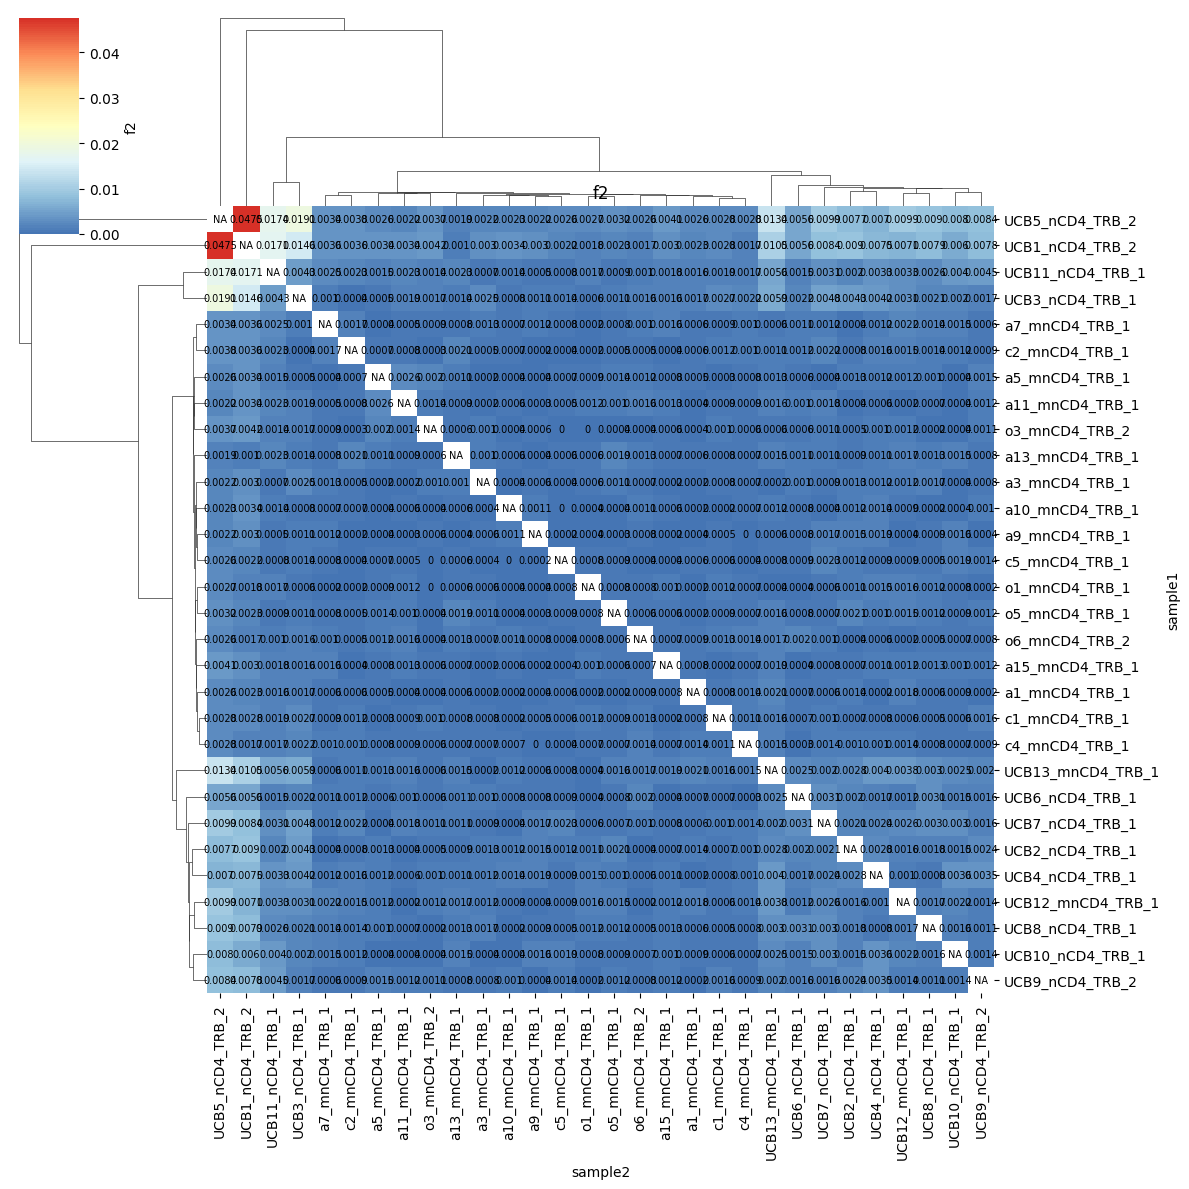

In [37]:
rsplot.beta_metric(beta_diversity, metric="f2", ignore_diagonal=True,
                   hclust=True, log_values=False, height=12)

In [38]:
# Усредняем сходство пар по группам без диагонали.
f2_pairs = f2.where(~np.eye(len(f2), dtype=bool)).stack().rename("f2").reset_index()
f2_pairs.columns = ["sample_id_1", "sample_id_2", "f2"]
group_by_sample = metadata.set_index("sample_id")["experimental_group"]
f2_pairs["group_1"] = f2_pairs["sample_id_1"].map(group_by_sample)
f2_pairs["group_2"] = f2_pairs["sample_id_2"].map(group_by_sample)
f2_pairs.groupby(["group_1", "group_2"], observed=True)["f2"].mean().unstack()

group_2,preterm,term,late,children,adults,older_adults
group_1,,,,,,
preterm,0.027333,0.007623,0.006609,0.002425,0.002373,0.002270
term,0.007623,0.002604,0.002446,0.001133,0.001086,0.001013
late,0.006609,0.002446,0.002066,0.001189,0.000988,0.000864
children,0.002425,0.001133,0.001189,0.000802,0.000672,0.000718
adults,0.002373,0.001086,0.000988,0.000672,0.000689,0.000838
older_adults,0.002270,0.001013,0.000864,0.000718,0.000838,0.000500


Сходство большинства пар низкое, медиана F2 равна 0,00108. Наибольшее среднее сходство внутри группы наблюдается в preterm, 0,0273; в term оно равно 0,00260, в late 0,00207. Максимум F2 составляет 0,0475 для пары UCB1_nCD4_TRB_2 и UCB5_nCD4_TRB_2 из preterm (более высокий F2 соответствует большему сходству)

### MDS for metric

In [39]:
ucb_mds = beta.mds(beta_diversity, metric="f2")
assert np.isfinite(ucb_mds[["MDS1", "MDS2"]]).all().all()
ucb_mds

,sample_id,MDS1,MDS2
0,UCB10_nCD4_TRB_1,-0.493706,0.600010
1,UCB11_nCD4_TRB_1,0.065263,-0.347142
2,UCB12_mnCD4_TRB_1,-0.171894,0.034775
3,UCB13_mnCD4_TRB_1,-0.021242,-0.346008
4,UCB1_nCD4_TRB_2,0.195418,0.292180
5,UCB2_nCD4_TRB_1,-0.253458,0.561354
6,UCB3_nCD4_TRB_1,0.041200,0.166911
7,UCB4_nCD4_TRB_1,0.115152,0.591848
8,UCB5_nCD4_TRB_2,-0.002914,0.129610
9,UCB6_nCD4_TRB_1,0.040470,0.650565


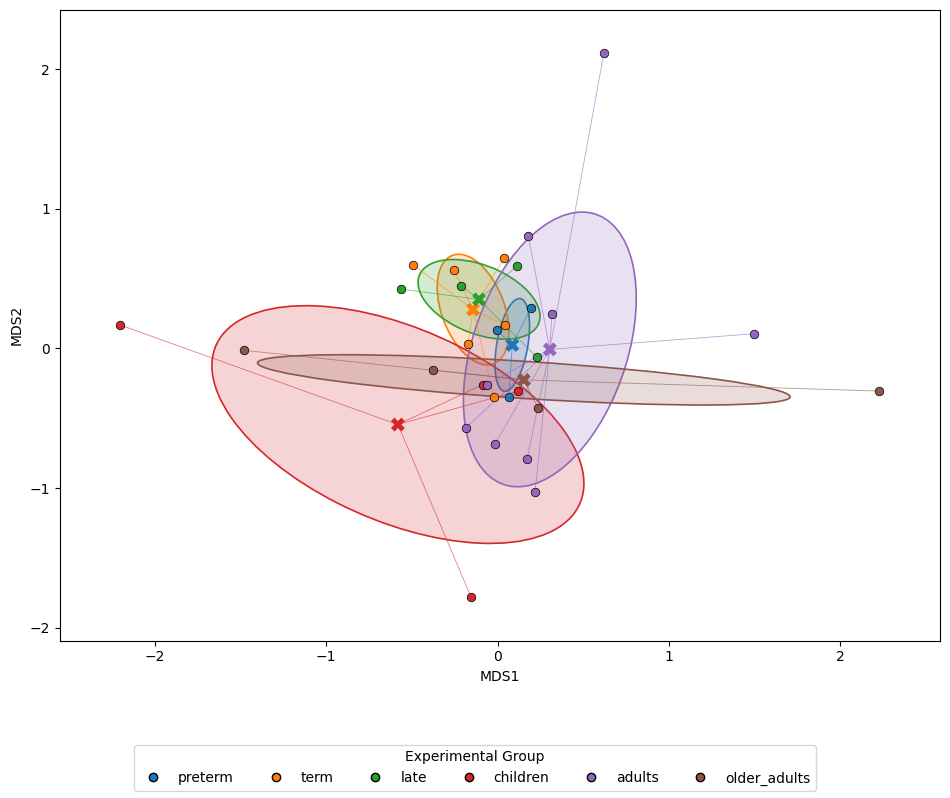

In [40]:
rsplot.beta_mds(ucb_mds, metadata=metadata, group="experimental_group", centroids=True, dispersion=True, height=8)

Области экспериментальных групп заметно перекрываются. Образцы UCB расположены преимущественно в центре, а children, adults и older_adults имеют больший разброс. Чёткого разделения всех групп нет

## Влияние downsample

In [41]:
downsample_small = 2500
small_filter = clf.Filter(functionality="f", downsample=downsample_small, by_umi=True)
diversity_small = stats.calc_diversity_stats(clonosets_subset, cl_filter=small_filter,
                                             iterations=3, seed=100, cpu=4)
depth_comparison = pd.concat([
    diversity_small.assign(downsample=downsample_small),
    diversity_stats.assign(downsample=downsample)], ignore_index=True).merge(metadata, on="sample_id")
depth_comparison.groupby(["experimental_group", "downsample"], observed=True)["diversity"].median().unstack()

CalcDiversityStats settings: seed=100, downsample=2500, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 4 cores


CalcClonosetStats |#-------------------------------------------------| 1/30 calcultaion(s) processed
CalcClonosetStats |###-----------------------------------------------| 2/30 calcultaion(s) processed


CalcClonosetStats |######--------------------------------------------| 4/30 calcultaion(s) processed


CalcClonosetStats |##########----------------------------------------| 6/30 calcultaion(s) processed
CalcClonosetStats |###########---------------------------------------| 7/30 calcultaion(s) processed


CalcClonosetStats |###############-----------------------------------| 9/30 calcultaion(s) processed
CalcClonosetStats |################----------------------------------| 10/30 calcultaion(s) processed
CalcClonosetStats |##################--------------------------------| 11/30 calcultaion(s) processed
CalcClonosetStats |####################------------------------------| 12/30 calcultaion(s) processed
CalcClonosetStats |#####################-----------------------------| 13/30 calcultaion(s) processed


CalcClonosetStats |#########################-------------------------| 15/30 calcultaion(s) processed
CalcClonosetStats |##########################------------------------| 16/30 calcultaion(s) processed
CalcClonosetStats |############################----------------------| 17/30 calcultaion(s) processed


... (11 outputs left out)

CalcDiversityStats |########################################----------| 24/30 calcultaion(s) processed
CalcDiversityStats |#########################################---------| 25/30 calcultaion(s) processed


CalcDiversityStats |#############################################-----| 27/30 calcultaion(s) processed
CalcDiversityStats |##############################################----| 28/30 calcultaion(s) processed


CalcDiversityStats |##################################################| 30/30 calcultaion(s) processed


downsample,2500,5000
experimental_group,,
preterm,2428.000000,4727.000000
term,2456.666667,4828.833333
late,2444.666667,4774.833333
children,2382.500000,4557.000000
adults,2432.000000,4720.666667
older_adults,2463.500000,4850.333333


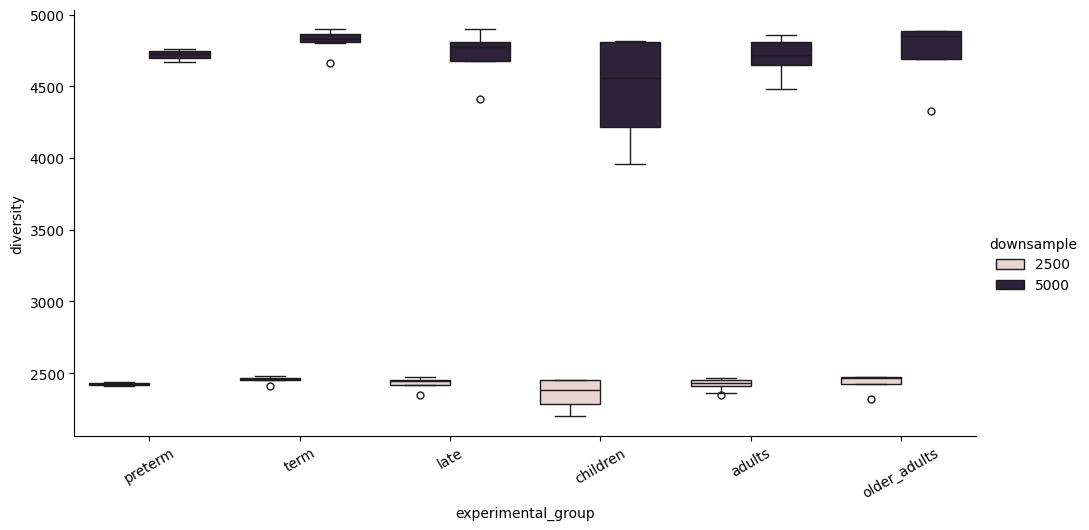

In [42]:
sns.catplot(data=depth_comparison, x="experimental_group", y="diversity", hue="downsample",
            kind="box", height=5, aspect=2)
plt.xticks(rotation=30)
plt.show()

При уменьшении глубины с 5000 до 2500 медианы diversity снижаются до 2383–2464. В обоих вариантах максимум остаётся у older_adults, минимум у children, а term занимает второе место. Близкие по diversity группы adults и preterm меняются местами. Поэтому их небольшое различие зависит от выбранной глубины.

## Выводы

Все 30 образцов вошли в анализ. Репертуары разнообразны, clonality низкая. При глубине 5000 медиана diversity максимальна в older_adults и минимальна в children. Эти крайние положения сохраняются при глубине 2500.

В preterm CDR3 короче, вставок меньше, а convergence выше. Во всех группах среди V-сегментов лидирует TRBV5-1. Наиболее частые J-сегменты в среднем по образцам имеют названия TRBJ2-1 и TRBJ2-7.

Среднее внутригрупповое сходство F2 выше всего в preterm. На MDS группы перекрываются. Различия описательные, статистическая значимость не проверялась. При сравнении UCB и периферической крови нужно учитывать различия сортировки nCD4 и mnCD4.